# Assignment 3 ? English?Hindi MT: results walkthrough

This notebook only reads saved artifacts; it does not retrain models or rerun inference.
Run it from the project root after the required artifacts exist, or use the saved outputs.

Sections: dataset stats and split audit ? exploratory data analysis ? headline metrics ? model comparison ? temperature ? error examples.


In [1]:
import json, sys
from pathlib import Path
import pandas as pd
from IPython.display import Image, display, Markdown

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
RES = ROOT / 'results'
print('project root: repository root')

project root: repository root


## 1. Dataset and split audit

IIT Bombay English–Hindi corpus, official provider splits, fixed 60k-pair shared training subset.

In [2]:
stats = json.loads((RES / 'data_stats.json').read_text(encoding='utf-8'))
display(pd.DataFrame({k: {'pairs': v['pairs'], 'src words (mean)': v['src_words']['mean'], 'tgt words (mean)': v['tgt_words']['mean']} for k, v in stats['splits'].items()}).T)
stats['leakage_audit']

,pairs,src words (mean),tgt words (mean)
train,60000.0,14.2,15.4
validation,520.0,17.7,17.9
test,2507.0,19.7,22.8


{'train_vs_val_source_overlap': 0,
 'train_vs_test_source_overlap': 0,
 'val_vs_test_source_overlap': 0,
 'method': 'Unicode NFKC + casefold + punctuation-strip + whitespace-fold; exact source sentence match required after normalisation'}

## 2. Exploratory data analysis

`scripts/15_eda.py` computes this descriptive view from the local processed TSVs after checking each file hash against `data/processed/dataset_manifest.json`; its recomputed length, unique-sentence, and Devanagari statistics match `results/data_stats.json`. The train plot describes the fixed 60,000-row shared subset (seed 42). Validation has 520 rows and the test split has 2,507 rows; headline metrics use a separate fixed 200-row test sample.

The processed splits have no blank pairs. Exact normalized pair repetitions are 0 in train, 0 in validation, and 1 additional row in test. The manifest records 51,232 train rows dropped during cleaning and 258,395 duplicate train pairs removed before selection of the 60,000-row subset. Median source/target word counts are 11/11, 16/16, and 18/20 (train/validation/test); median character counts are 59/57, 97.5/82, and 107/104. Devanagari makes up about 99.15%, 100.00%, and 99.53% of target alphabetic characters. Length and script patterns describe this dataset only; they do not assess translation adequacy, representativeness, or systematic bias.

![Sentence-length distributions and Hindi-target script composition](../results/figures/dataset_eda.png)


,rows,missing pairs,normalized pair duplicates,unique source,unique target,median words src/tgt,median chars src/tgt,mean target Devanagari ratio,target letters Devanagari %,target letters Latin %
split,,,,,,,,,,
train,60000,0,0,57503,56884,11.0/11.0,59.0/57.0,0.9881,99.15,0.85
validation,520,0,0,520,520,16.0/16.0,97.5/82.0,1.0000,100.00,0.00
test,2507,0,1,2506,2506,18.0/20.0,107.0/104.0,0.9958,99.53,0.47


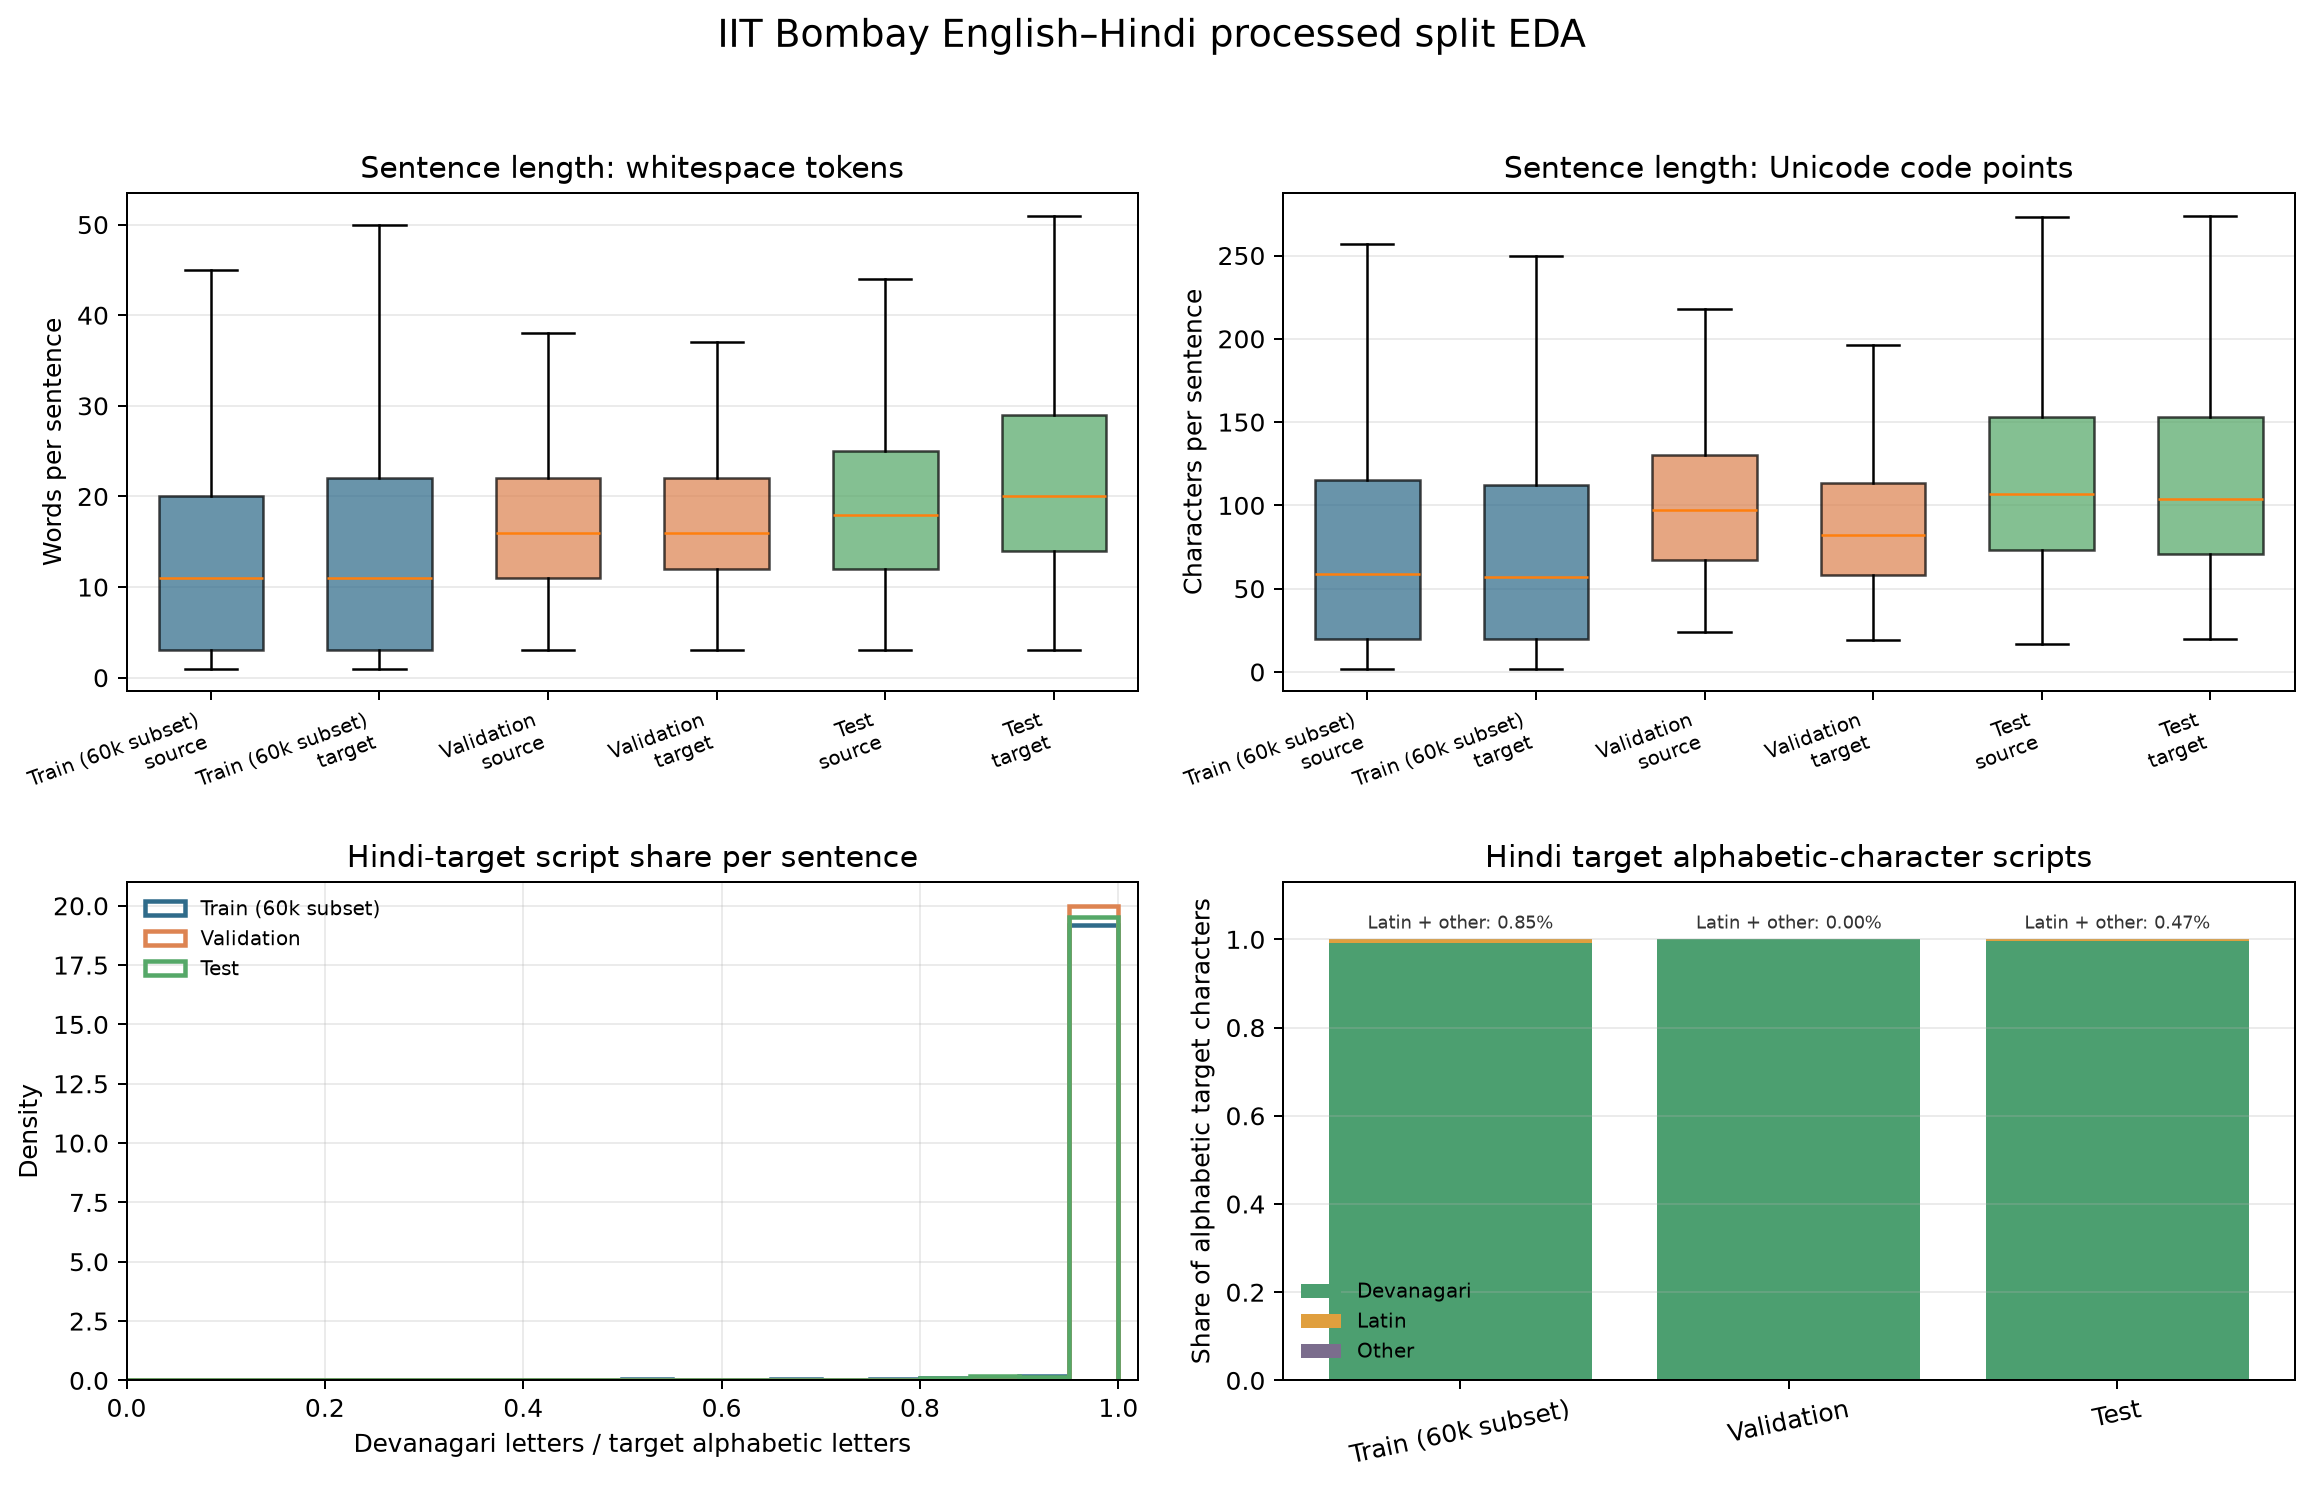

In [3]:
eda = json.loads((RES / 'eda_summary.json').read_text(encoding='utf-8'))
eda_rows = []
for split, values in eda['splits'].items():
    shares = values['target_alphabetic_script_letter_shares']
    eda_rows.append({
        'split': split,
        'rows': values['rows'],
        'missing pairs': values['missing_pairs'],
        'normalized pair duplicates': values['normalized_exact_pair_duplicate_rows'],
        'unique source': values['unique_source_sentences'],
        'unique target': values['unique_target_sentences'],
        'median words src/tgt': f"{values['source_words']['p50']}/{values['target_words']['p50']}",
        'median chars src/tgt': f"{values['source_characters']['p50']}/{values['target_characters']['p50']}",
        'mean target Devanagari ratio': values['target_devanagari_ratio_per_sentence']['mean'],
        'target letters Devanagari %': round(100 * shares['devanagari'], 2),
        'target letters Latin %': round(100 * shares['latin'], 2),
    })
display(pd.DataFrame(eda_rows).set_index('split'))
display(Image(filename=str(ROOT / eda['figure'])))


## 3. Headline results

BLEU (13a), chrF, and 95% sentence-level bootstrap CIs use the same fixed 200-row sample drawn from the full 2,507-row test split. The split contains 2,507 rows; the fixed headline sample contains 200 rows.


,system,architecture,params_m,train_or_adapt_s,inference_s,bleu,chrf,ter
0,Basic Transformer (from scratch),encoder-decoder,15.2,463.9,15.070,0.262,9.624,145.377
1,mT5-small (fine-tuned),encoder-decoder,300.2,12379.4,128.950,7.581,29.335,82.141
2,TinyLlama 1.1B (3-shot prompt),decoder-only,1100.0,NaN,389.144,0.358,13.663,118.142
3,Gemma 3 1B (3-shot prompt),decoder-only,999.9,NaN,250.850,10.952,35.566,84.998


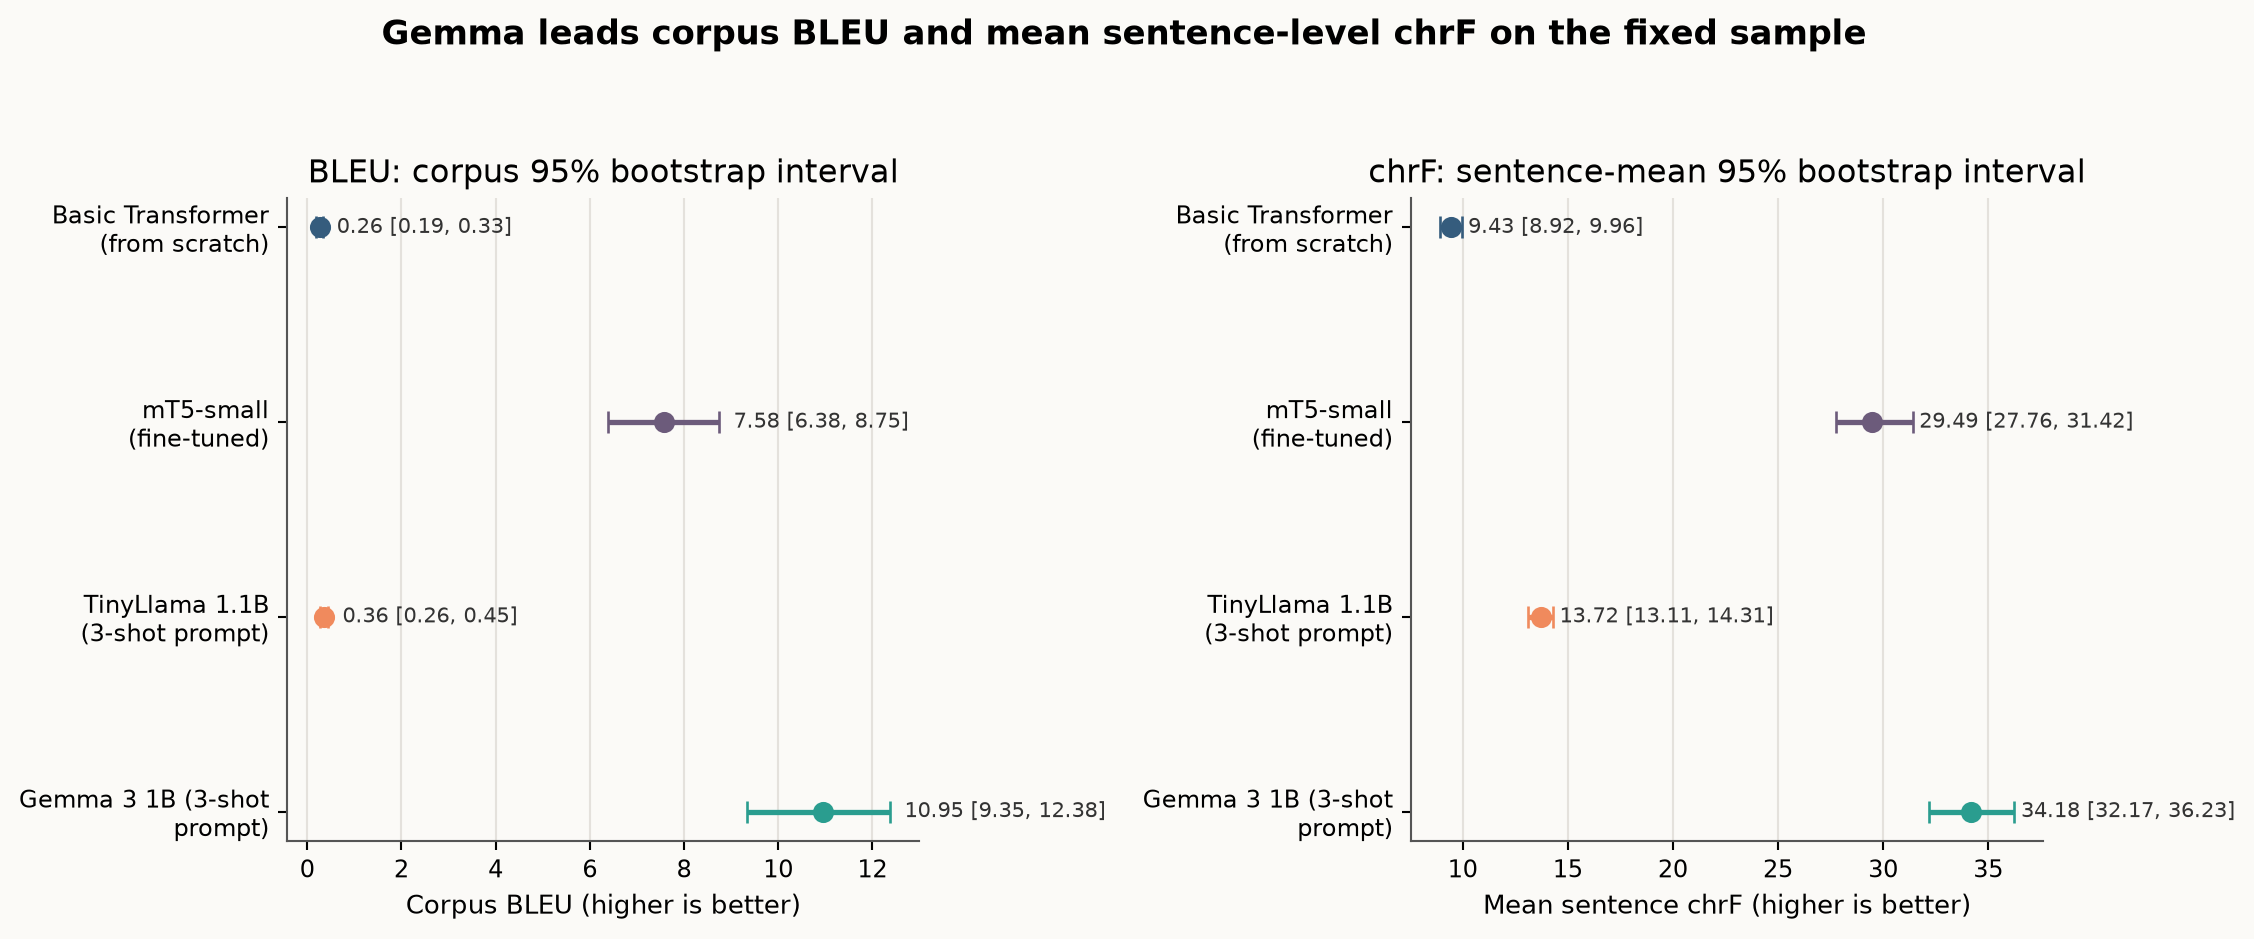

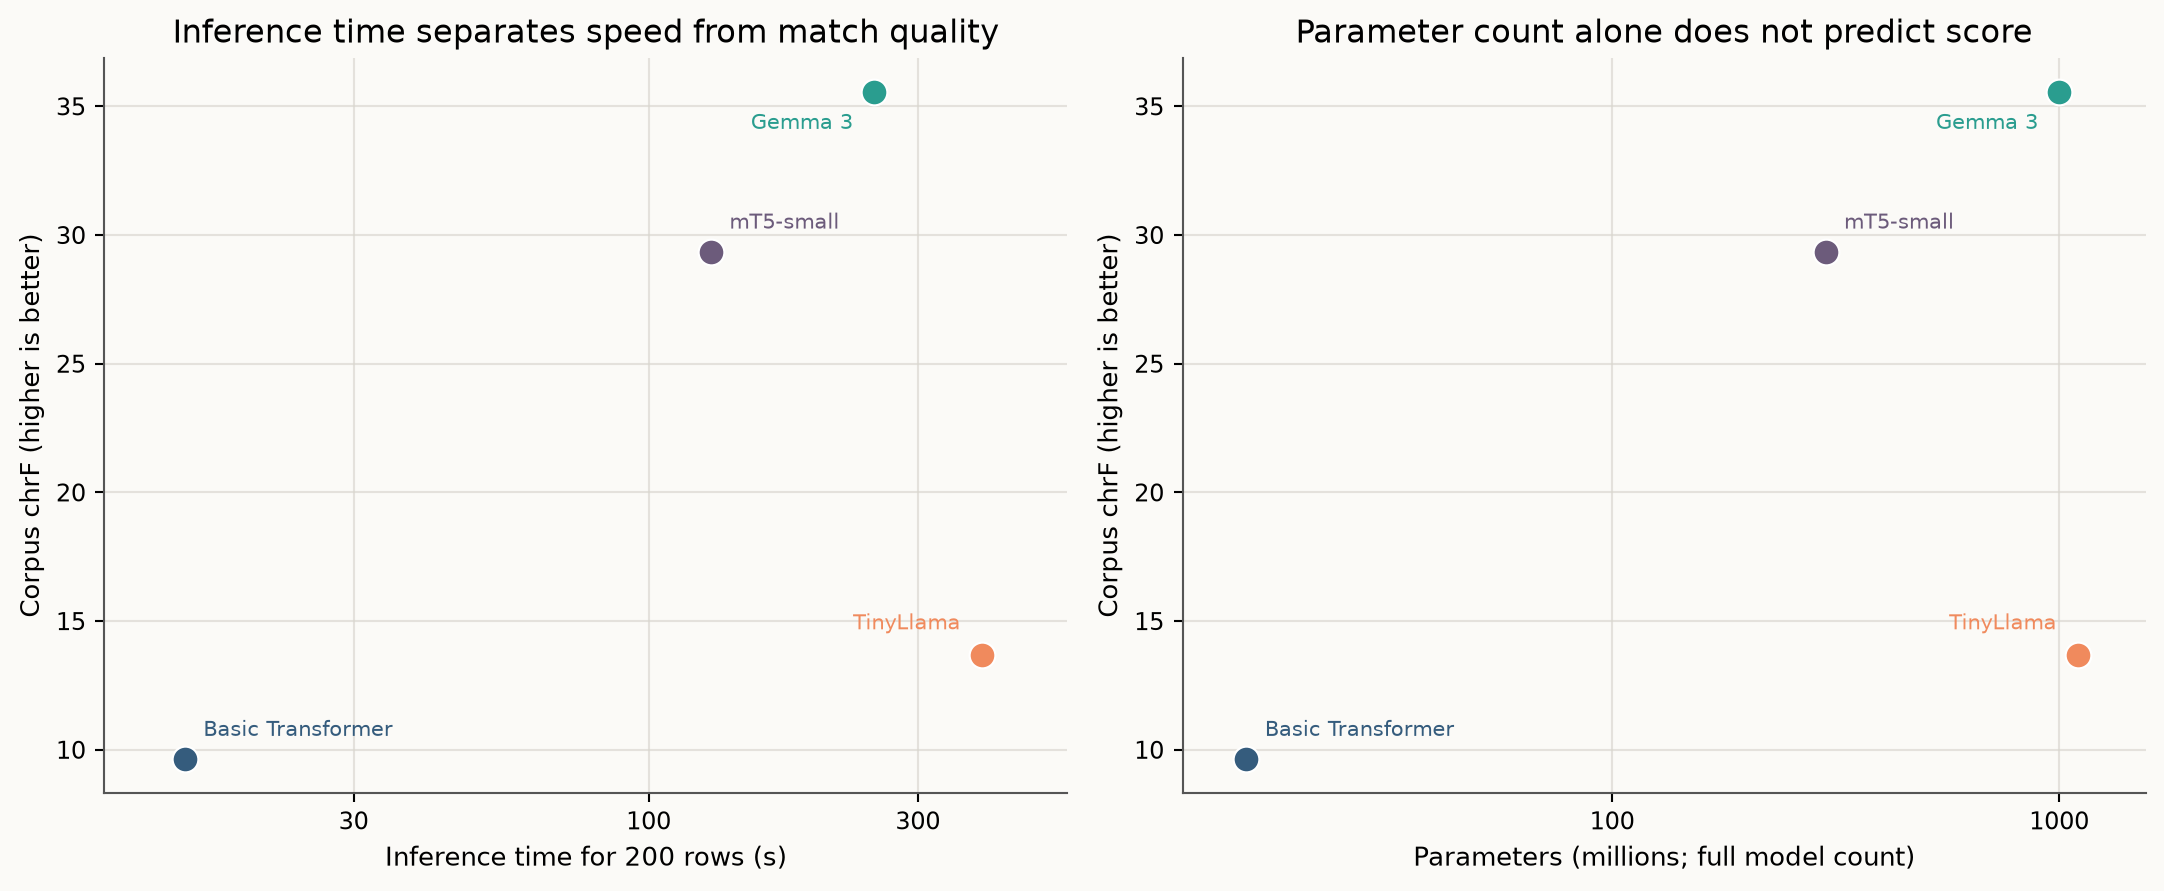

In [8]:
df = pd.read_csv(RES / 'summary_table.csv')
display(df[['system','architecture','params_m','train_or_adapt_s','inference_s','bleu','chrf','ter']])
display(Image(filename=str(RES / 'figures' / 'score_intervals.png')))
display(Image(filename=str(RES / 'figures' / 'quality_cost.png')))

## 4. Generated translations (inspect, do not trust aggregate scores alone)

Every system translated the identical test rows in the identical order.

In [5]:
import itertools
def load(name):
    path = RES / 'translations' / f'{name}.jsonl'
    return [json.loads(l) for l in path.read_text(encoding='utf-8').splitlines()] if path.exists() else []

systems = ['basic_transformer','mt5_base','llama_prompt3shot','gemma_prompt3shot']
rows = {s: load(s) for s in systems}
for i in range(3):
    print('SRC :', rows['basic_transformer'][i]['src'])
    print('REF :', rows['basic_transformer'][i]['ref'])
    for s in systems:
        if rows[s]:
            print(f'{s:18s}:', rows[s][i]['hyp'])
    print('-' * 100)


SRC : The devices, which track every mile a motorist drives and transmit that information to bureaucrats, are at the center of a controversial attempt in Washington and state planning offices to overhaul the outdated system for funding America's major roads.
REF : यह डिवाइस, जो मोटर-चालक द्वारा वाहन चलाए गए प्रत्येक मील को ट्रैक करती है तथा उस सूचना को अधिकारियों को संचारित करती है, आजकल अमेरिका की प्रमुख सड़कों का वित्त-पोषण करने के लिए पुराने हो चुके सिस्टम का जीर्णोद्धार करने के लिए वाशिंगटन और राज्य नियोजन कार्यालय के लिए एक विवादास्पद प्रयास का मुद्दा बन चुका है।
basic_transformer : इस प्रकार के लिए, धारी के लिए, धारा के लिए, धारा, धारी के साथ, धारी के साथ, धारा के लिए, धारित किया जाता है।
mt5_base          : यह उपकरण, जो प्रत्येक मील पर एक मोटरचालक ड्राइव चलाते हैं और यह जानकारी अमेरिका के प्रमुख मार्गों को बढ़ावा देते हैं और अमेरिका के प्रमुख मार्गों को बढ़ावा देते हैं।
llama_prompt3shot : इस्‍तेमाल के साथ जानें उनको इस देश के बढ़ते स्‍तरों के समझौता के साथ इस्‍तेमाल से उनको इस 

## 5. Sampling-temperature analysis

The saved temperature study compares reference scores and output diversity on the same fixed 20-row subset; it is descriptive and does not establish a universal decoding optimum.

llama_prompt3shot


,temperature,bleu,chrf,distinct_1,distinct_2,mean_words,empty_rate
0,0.2,0.408,13.861,0.3212,0.6481,26.15,0.0
1,0.7,0.568,15.531,0.5234,0.8998,22.45,0.0
2,1.0,0.559,15.436,0.6495,0.9798,23.25,0.0


gemma_prompt3shot


,temperature,bleu,chrf,distinct_1,distinct_2,mean_words,empty_rate
0,0.2,12.462,38.772,0.6120,0.9490,22.55,0.0
1,0.7,10.259,35.902,0.5876,0.9375,23.40,0.0
2,1.0,8.826,34.734,0.5983,0.9330,23.40,0.0


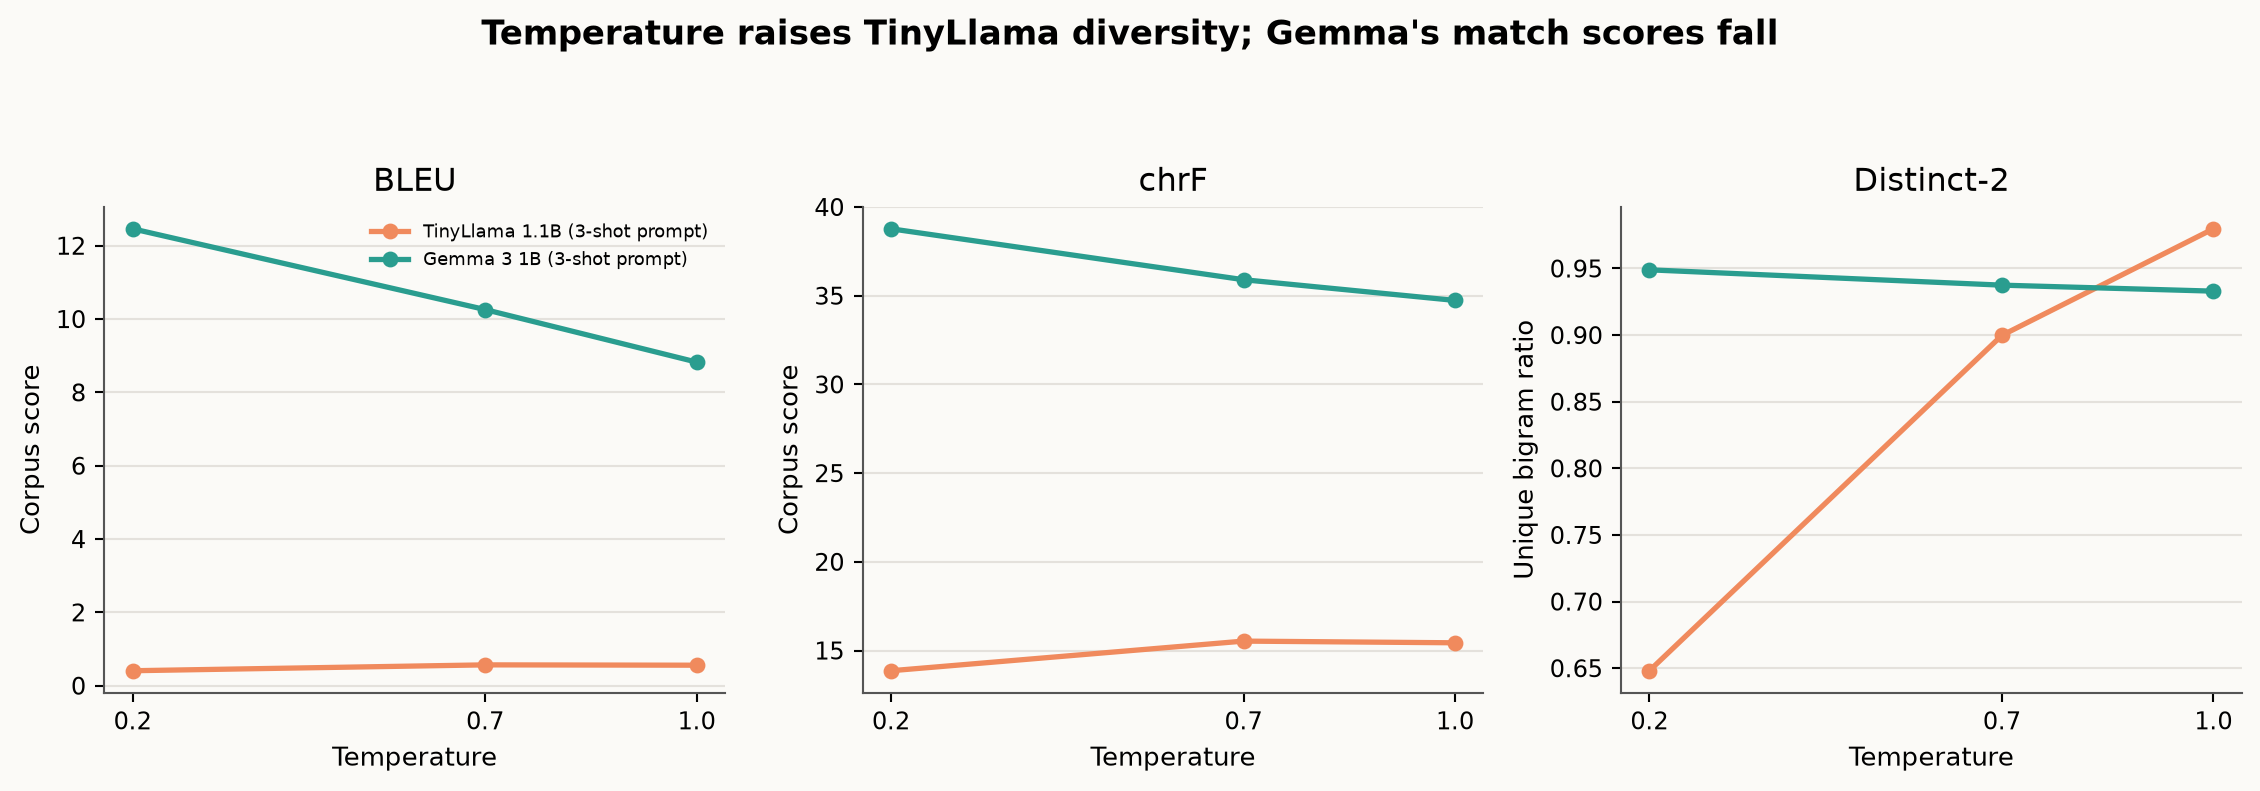

In [9]:
temp_path = RES / 'temperature' / 'temperature_results.json'
if temp_path.exists():
    temp = json.loads(temp_path.read_text(encoding='utf-8'))
    for system, rows_ in temp.get('results', temp).items():
        print(system)
        display(pd.DataFrame(rows_)[['temperature','bleu','chrf','distinct_1','distinct_2','mean_words','empty_rate']])
    display(Image(filename=str(RES / 'figures' / 'temperature_analysis.png')))

## 6. Responsible-AI screening

Automatic flags are screening aids; the qualitative judgements in `docs/report.md` come from reading the outputs in `results/error_analysis/flagged_examples.md`.

In [7]:
flags = json.loads((RES / 'error_analysis' / 'risk_flags.json').read_text(encoding='utf-8'))
display(pd.DataFrame(flags).T[['n','no_devanagari','dropped_number_sentences','added_number_sentences','untranslated_latin_sentences','repetition_loops']])

,n,no_devanagari,dropped_number_sentences,added_number_sentences,untranslated_latin_sentences,repetition_loops
basic_transformer,200.0,0.000,0.180,0.090,0.000,0.470
mt5_base,200.0,0.000,0.065,0.040,0.010,0.065
llama_prompt3shot,200.0,0.000,0.140,0.000,0.005,0.225
gemma_prompt3shot,200.0,0.055,0.020,0.015,0.140,0.005


## Figures used in the README and report

The figures below are generated from saved evaluation artifacts. No training or inference is needed to display them.

![Pipeline diagram](../results/figures/pipeline_flow.png)

One sample of 200 rows is shared across four systems.

![Dataset EDA](../results/figures/dataset_eda.png)

The test split has median lengths of 18 source words and 20 target words.

![Architecture and prompt](../results/figures/architecture_comparison.png)

The encoder-decoder models have 15.2M and 300.2M parameters; each decoder prompt uses three examples.

![Training curves](../results/figures/training_curves.png)

The scratch model's best validation loss is 6.1463; mT5's last recorded validation loss is 2.2517.

![Score intervals](../results/figures/score_intervals.png)

Gemma leads corpus BLEU at 10.952; its mean sentence chrF is 34.180.

![Quality and cost](../results/figures/quality_cost.png)

Gemma has corpus chrF 35.566 in 250.85 seconds; the scratch Transformer has 9.624 chrF in 15.07 seconds.

![Sentence chrF distribution](../results/figures/sentence_chrf_distribution.png)

Mean sentence chrF is 34.180 for Gemma and 9.432 for the scratch Transformer.

![chrF by source length](../results/figures/chrf_by_source_length.png)

The 31+ word bucket contains 23 examples, so its mean is less stable than the larger buckets.

![Paired BLEU bootstrap](../results/figures/paired_bleu_bootstrap.png)

The Basic Transformer minus TinyLlama interval includes zero; mT5 minus Gemma does not.

![Tokenizer fertility](../results/figures/tokenizer_fertility.png)

TinyLlama averages 5.55 Hindi tokens per word; Gemma averages 1.364.

![Risk flags](../results/figures/risk_flag_heatmap.png)

Repetition flags occur in 47.0% of scratch outputs and 0.5% of Gemma outputs.

![Temperature analysis](../results/figures/temperature_analysis.png)

On 20 rows, Gemma BLEU falls from 12.462 at temperature 0.2 to 8.826 at 1.0.
